In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # the folder above this notebook
import numpy as np 
import tensorflow as tf
import timeit
import matplotlib.pyplot as plt
from utils.config import GameConfig, GAME_DEFS
from utils.models import build_main_model, display_strat
from utils.utils import make_optimizer, make_training_data, make_two_sample_data
from utils.training import train
from utils.evaluation import *
from utils.lossFunctions import *
from utils.results import *
import time


In [2]:
# l2_alpha =0.0
# l2_alpha =1e-6
CONFIG = GameConfig(
    game="asym2",
    optimizer="sgd",
    max_iters=1_000,
    run_n=f"uniformfast_oct5",
    seed=2,
    sgd_alpha_0 = 1e-3,
    # adam_lr= 1e-4,
    # For Pareto
    # two_sample=True,
    # own_dist= "stratified_pareto",
    # opp_dist= "pareto",
    m=1000, 
    batch_size=500,
    # strat_floor=1
)

In [3]:
game_def = GAME_DEFS[CONFIG['game']]
designed_initializer = tf.keras.initializers.RandomUniform(minval=-0.5, maxval=0.5)
main_model = build_main_model(game_def, designed_initializer, 0.0)

/Users/andresho/Desktop/Continuous-Type-BNE/venv/lib/python3.9/site-packages/keras/src/initializers/initializers.py:120: UserWarning: The initializer RandomUniform is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


In [4]:
t0 = time.perf_counter()
optimizer = make_optimizer(CONFIG)

if CONFIG.two_sample: # pareto
    theta_own, theta_opp = make_two_sample_data(game_def, CONFIG)
    checkpointer = train(main_model, optimizer, game_def, CONFIG,
                         theta_own=theta_own, theta_opp=theta_opp, save_weight_every=10_000)
else:
    training_data = make_training_data(game_def, CONFIG['m'], CONFIG['seed'])
    checkpointer = train(main_model, optimizer, game_def, CONFIG,
                         training_data=training_data, save_weight_every=10_000)

dt = time.perf_counter() - t0
print(f"{CONFIG['max_iters']} iterations: {dt:.1f} s  ({CONFIG['max_iters'] / dt:.1f} it/s)  ->  1M iterations ≈ {dt / CONFIG['max_iters'] * 1_000_000 / 3600:.1f} h")

No checkpoint found, starting from scratch.
Saved training data to /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniformfast_oct5/training_data.npy
Training steps 1 to 1,000
Saved checkpoint at step 1000: /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniformfast_oct5/checkpoint_dir/ckpt-1
Trained through iteration 1000
1000 iterations: 6.4 s  (156.0 it/s)  ->  1M iterations ≈ 1.8 h


Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniformfast_oct5/checkpoint_dir/ckpt-1 (step 1000)
[model] /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniformfast_oct5/checkpoint_dir/ckpt-1 (step 1,000)

=== single_check: weights ===
                 model          
              Player 1  Player 2
dense_1      5.009e-01 5.014e-01
dense_2      4.999e-01 5.003e-01
dense_3      5.000e-01 4.997e-01
dense_4      4.998e-01 4.999e-01
dense_5      5.000e-01 4.999e-01
dense_6      4.999e-01 4.999e-01
dense_7      5.000e-01 5.004e-01
output_layer 5.001e-01 4.996e-01

=== single_check: spectral ===
                    model          
                 Player 1  Player 2
dense_1         2.332e+00 2.330e+00
dense_2         4.520e+00 4.520e+00
dense_3         4.520e+00 4.520e+00
dense_4         4.520e+00 4.519e+00
dense_5         4.520e+00 4.520e+00
dense_6         4.520e+00 4.520e+00
dense_7         4.520e+00 4.520e+00
output_layer    2.334e+0

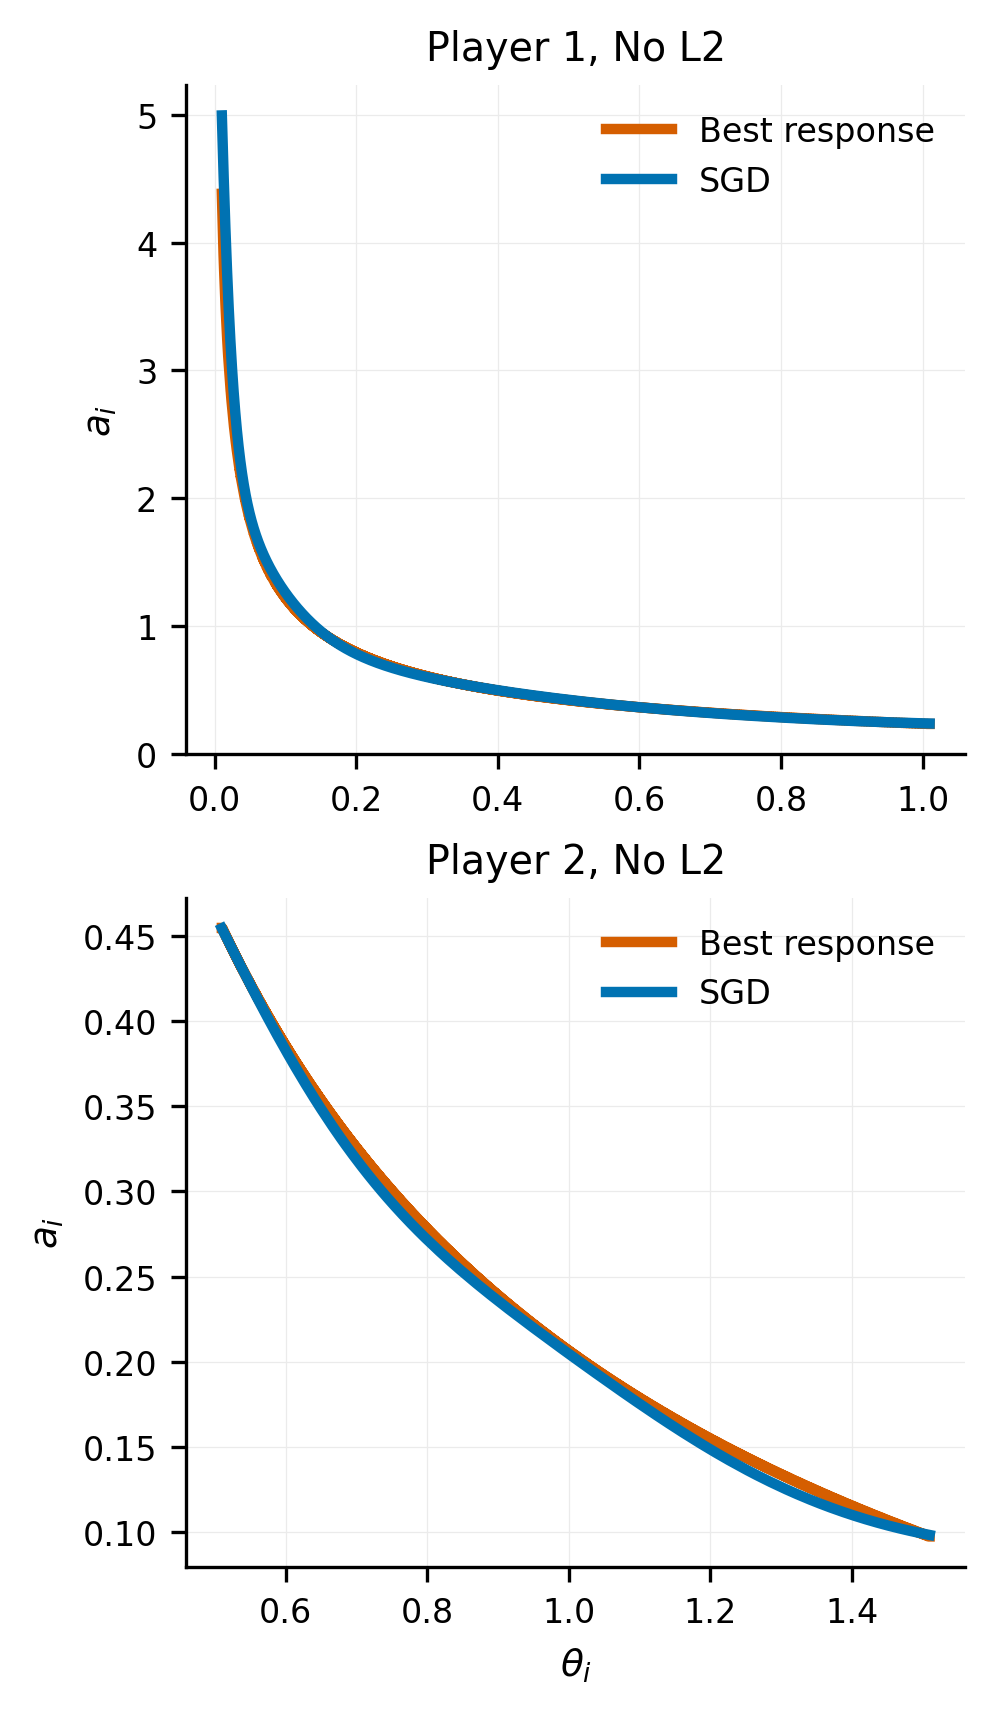

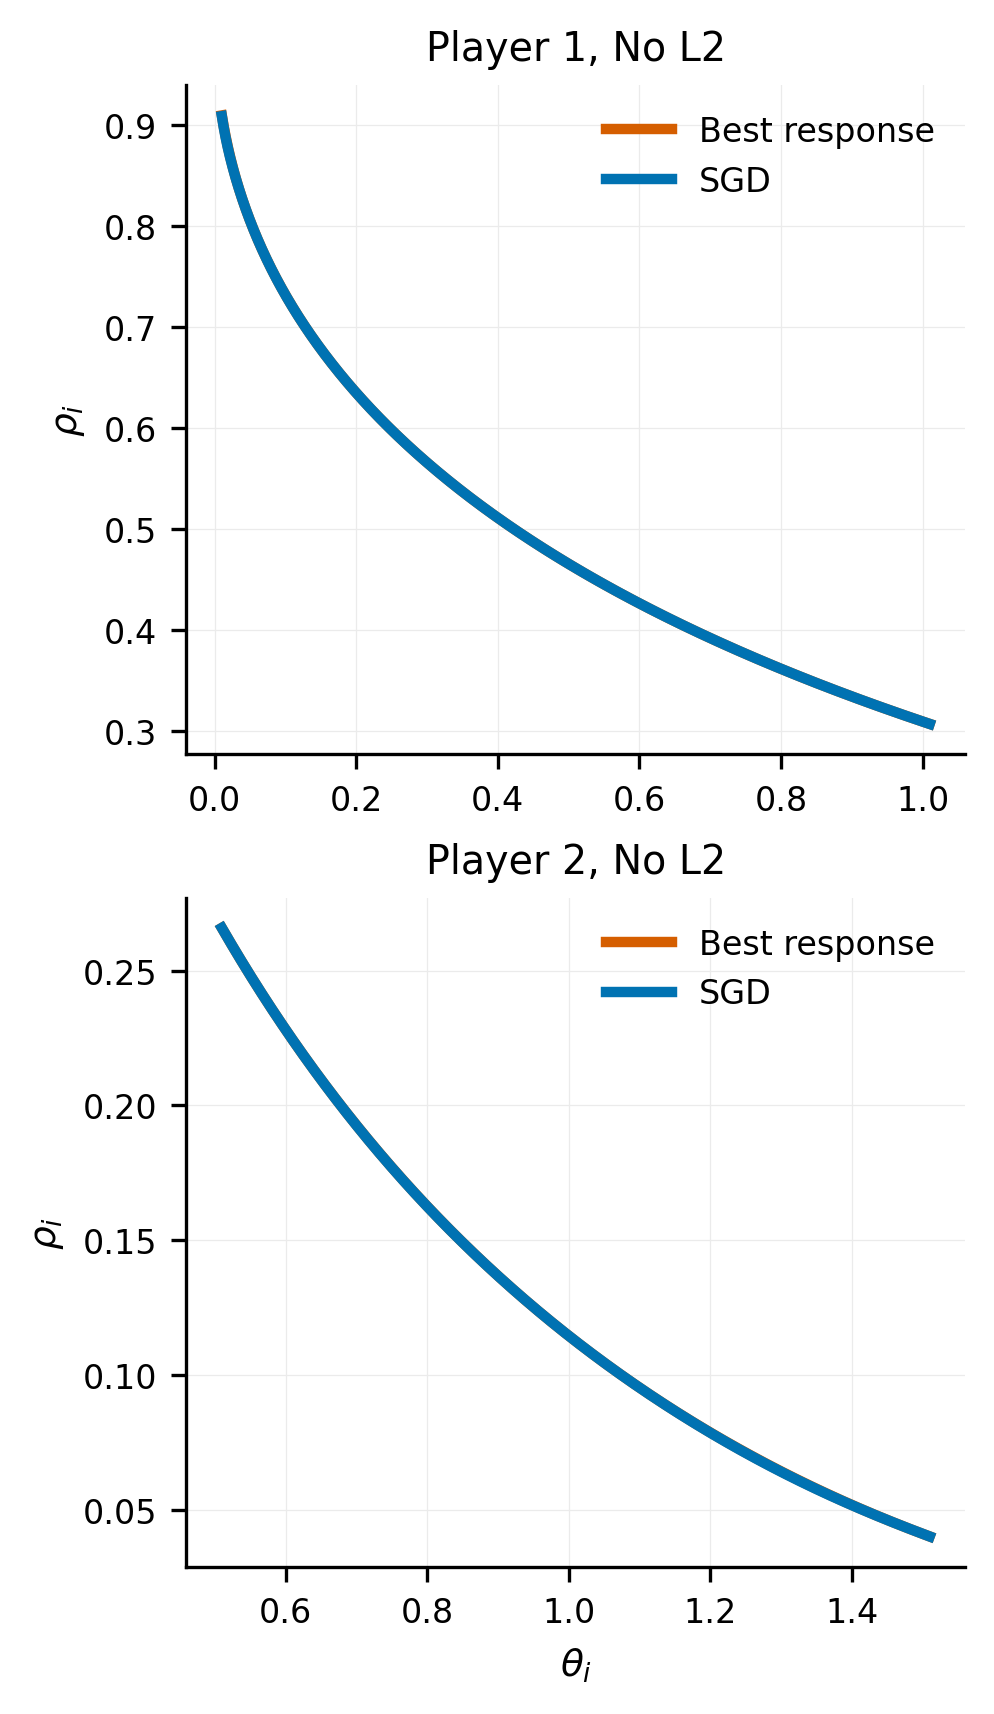

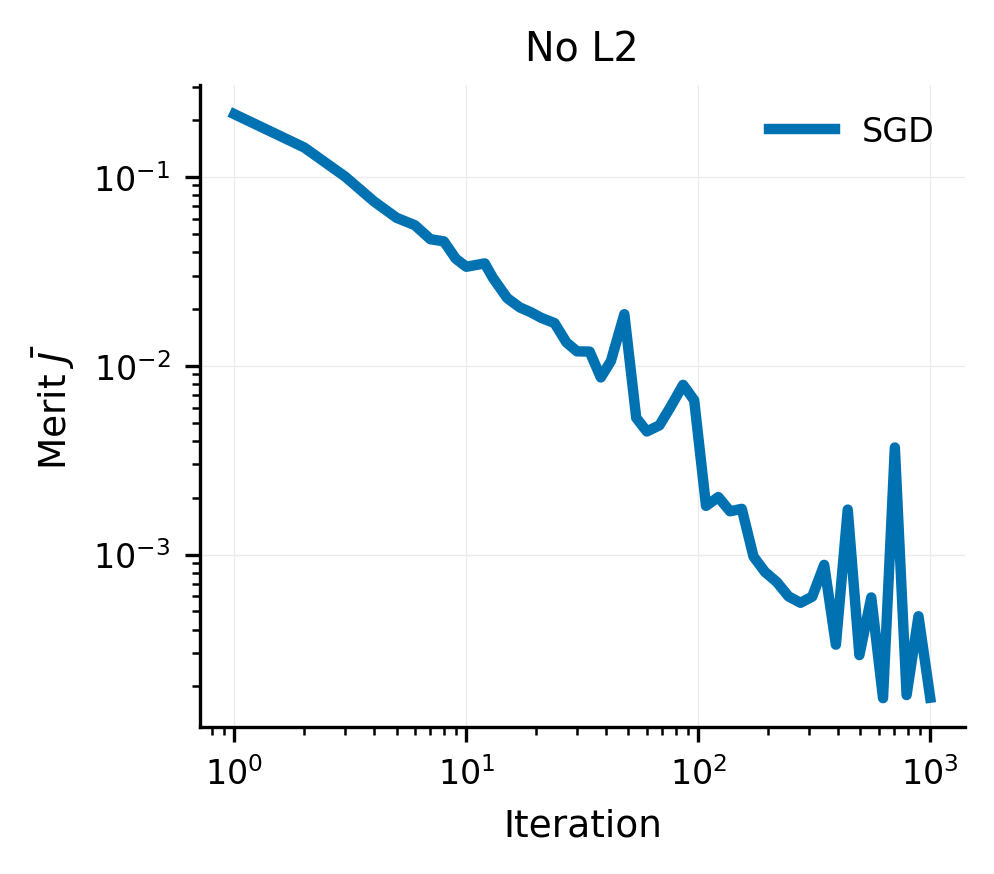

In [6]:
from utils.results import evaluate_run
from utils.tables import experiment_tables
from utils.figures import experiment_figures

r = evaluate_run("model", CONFIG, 0.0)      # loads the latest checkpoint for CONFIG
experiment_tables([r], "single_check")            # merit, relative losses (uniform and prior), tail, epsilon
experiment_figures([r], "single_check")           # strategy, utilities, training curve